# Return forecasting and conditional volatility

This notebook evaluates aggregate rolling one-step-ahead forecasting metrics and conditional-variance model-selection counts. No private forecasts or parameters are distributed.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
here=Path.cwd().resolve()
ROOT=next((p for p in (here,*here.parents) if (p/'results/rolling_forecast_accuracy.csv').exists()),None)
if ROOT is None: raise FileNotFoundError('Run notebook from the public repository or its notebooks directory')


## Rolling one-step return forecasts

Results use independent evaluation windows for daily and monthly frequencies. Lower RMSE and MAE are better.


,frequency,model,n,rmse,mae,direction_accuracy
5,daily,predicted,126,0.00753,0.00587,0.50000
6,daily,baseline_mean,126,0.00754,0.00590,0.50000
7,daily,baseline_zero,126,0.00756,0.00589,0.50000
8,daily,baseline_last,126,0.01097,0.00868,0.50000
0,monthly,baseline_mean,12,0.02734,0.02368,0.75000
1,monthly,predicted,12,0.03051,0.02679,0.66667
2,monthly,baseline_zero,12,0.03108,0.02604,0.25000
3,monthly,baseline_last,12,0.03183,0.02626,0.75000
4,monthly,daily_arimax,12,0.04006,0.03238,0.50000


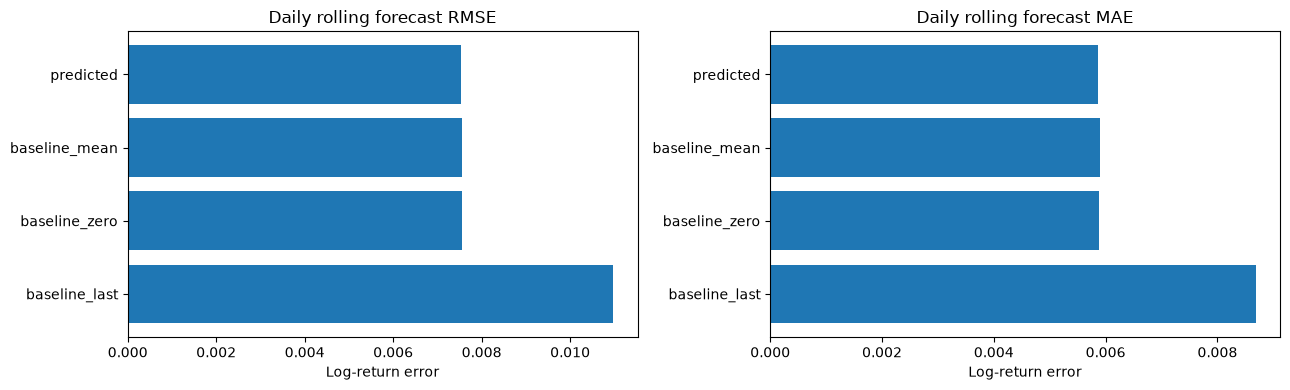

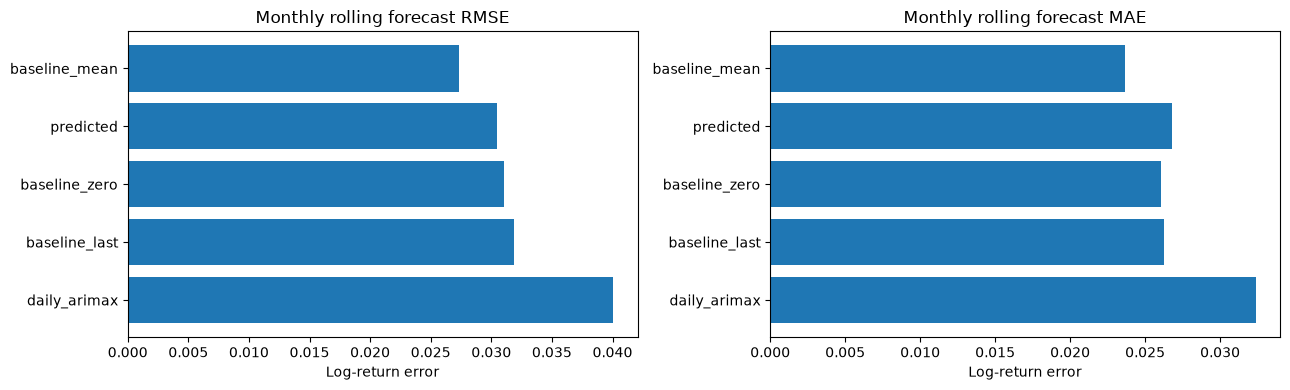

In [2]:
forecast=pd.read_csv(ROOT/'results/rolling_forecast_accuracy.csv')
display(forecast.sort_values(['frequency','rmse']).round(5))
for freq,g in forecast.groupby('frequency'):
    fig,axs=plt.subplots(1,2,figsize=(13,4))
    g=g.sort_values('rmse')
    for ax,metric in zip(axs,['rmse','mae']):
        ax.barh(g.model,g[metric]);ax.invert_yaxis();ax.set_title(freq.title()+' rolling forecast '+metric.upper());ax.set_xlabel('Log-return error')
    fig.tight_layout();plt.show()


## Conditional variance selection

The published counts describe models selected in the saved monthly volatility study, not proof of superior risk forecasts. Variance losses require paired realised innovations and predicted variances, which are not published.


,method,n
0,"GJR-GARCH(1,1)-t",6
1,"EGARCH(1,1)-t",5
2,"GARCH(1,1)-t",1


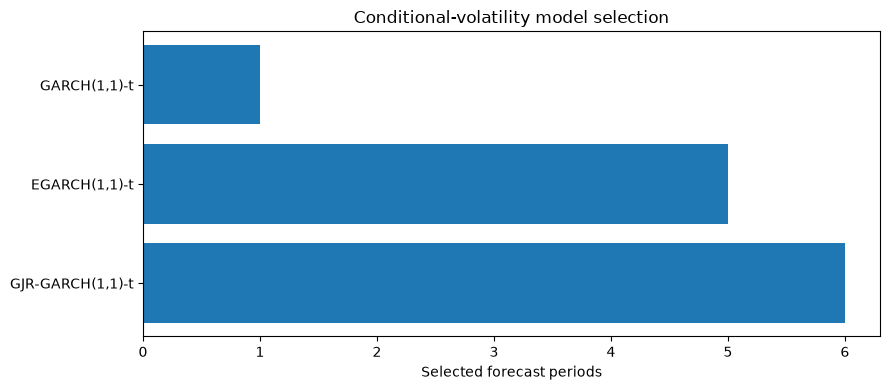

In [3]:
vol=pd.read_csv(ROOT/'results/volatility_model_selection.csv')
display(vol)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(vol.method,vol.n);ax.set_xlabel('Selected forecast periods');ax.set_title('Conditional-volatility model selection');fig.tight_layout();plt.show()


## Interpretation

Error reductions must be assessed against simple baselines on the same dates. Short monthly holdouts do not provide persuasive evidence of reliable predictability.
